In [55]:
from skyfield.api import load, wgs84
import numpy as np
from numpy import array2string
from datetime import datetime, timedelta
import os
from scipy import io as sio
import pytz
import math
import scipy.io
from tqdm import tqdm
import aoa
from matplotlib import pyplot as plt

In [2]:
# TODO: define constants and set other parameters
c = 299792458.0 # speed of light in m/s
fc = 11.575e9 # carrier frequency in Hz
f = 0.2e6 # narrowband tone freq in Hz
lo = 9.75e9 # local oscillator frequency in Hz
fs = 1e3 # sampling frequency in Hz
lam = c/fc # wavelength in m
d = lam/2 # antenna spacing in m
re = 6378e3 # earth radius in m
min_elevation = 60 # minimum elevation of visible sats


In [3]:
# Load tle from path

# change the path
# path = '/Users/ishani/UIUC/Research/starlink_ofdm/AoA_Sim/tles/10_31/STARLINK-6150.tle'
path = 'D:\\Desktop\\study\\2023_summer\\starlink_ofdm\\AoA_Sim\\tles\\10_31\\STARLINK-6150.tle'

satellites = load.tle_file(path)
print(satellites)

# % assume we have 4 synchronized LNBs, placed in the following way:
#  ------------         N
# | LNB2 LNB4 |       W + E
# | LNB1 LNB3 |         S
#  ------------
# initialize location of 4 LNBs with lat, lon = +40.11389690596162, -88.22484814695467 (UIUC)
lat_1, lon_1 = +40.11389690596162, -88.22484814695467
lnb_1 = wgs84.latlon(lat_1, lon_1)
lnb_2 = wgs84.latlon(lat_1+math.degrees(d/re), lon_1)
lnb_3 = wgs84.latlon(lat_1, lon_1+math.degrees(d/re)/math.cos(math.radians(lat_1)))
lnb_4 = wgs84.latlon(lat_1+math.degrees(d/re), lon_1+math.degrees(d/re)/math.cos(math.radians(lat_1)))
lnbs = [lnb_1, lnb_2, lnb_3, lnb_4]

# set start time and stop time, add 5 hours to account for time zone difference
ts = load.timescale()
start_time = datetime(2023, 10, 31, 0, 0, 0, tzinfo=pytz.UTC)+timedelta(hours=5) 
stop_time = datetime(2023, 10, 31, 0, 1, 0, tzinfo=pytz.UTC)+timedelta(hours=5)

[<EarthSatellite STARLINK-6150 catalog #57119 epoch 2023-10-31 06:43:42 UTC>]


The following section tries to estimate the AoA (both azimuth & elevation) using MUSIC.

Assume that the satellite is transmitting at frequency $f_c+f=11.575 GHz+0.2 MHz$, i.e.,
$$y(t) = \exp(j2\pi(f+f_c)t),$$
where $f_c$ is the carrier frequency and $f$ is the narrowband tone's frequency.

The received signal at LNB-i at UIUC (i=1,2,3,4) is
$$y_i(t) = Ay(t-r_i/c)+n_i = A\exp(j2\pi(f+f_c)(t-r_i/c))+n_i,$$
where $A$ is path loss, $n_i$ is the noise at LNB-i, $r_i$ is the distance between the satellite and the LNB-i. (TODO: $r_i$ should be the distance at time $t$ or some $t'$ s.t. $t'\times c=r_i(t')$)

$$y_i(t) = A\exp(j2\pi(f+f_c)\times (t-r_i/c))+n_i, \\
 = A\exp(-j2\pi(f+f_c)r_i/c)\times \exp(j2\pi(f+f_c)t)+n_i, \\
 = A'\exp(j2\pi(f+f_c)t)+n_i.$$

$y_i(t)$ is in anaglog domain, then LNB \& USRP down-converts it at sample it. In the most ideal case where we have synchronized LNBs and USRPs, the digital signal we get is removing $f_c$ and substituting continuous time $t$ with discrete time samples $n T_s = n/F_s$, i.e.,
$$y_i[n] = A'\exp(j2\pi f n/f_s)+n_i,$$
from where we start our simulation

In [4]:
# generate received signal
# get start time as ts.utc
t = ts.utc(start_time)
duration = stop_time-start_time
n_list = np.arange(0, fs*duration.total_seconds(), 1).astype(int)
num_antennas = len(lnbs)

# received_sig and d are 2-D matrix, row index means different lnb and column index means different time steps
# received_sig_i = received_sig[i-1, :], for i = 1, 2, ... 
received_sig = np.empty((num_antennas, len(n_list)), dtype=np.complex64)
dis = np.empty((num_antennas, len(n_list)))

for n in tqdm(n_list):

    for m in range(num_antennas):

        lnb = lnbs[m]
        dist = (satellites[0]-lnb).at(t)
        el, az, distance = dist.altaz()

        _, _, the_range, _, _, range_rate = dist.frame_latlon_and_rates(lnb)
        doppler_shift = (fc)*range_rate.km_per_s*1000/c

        # print(doppler_shift)
        # print(the_range.km)
        # generate received signal TODO: double check (checked)
        # received_sig_0 = np.exp(-1j*2*np.pi*(fc+f+doppler_shift)*(n[i]/fs+the_range.km/c)) # TODO: can comment this out
        # downconvert to baseband : for now we assume that the effect of doppler shift is equivalent on all lnbs and will cancel out when calculating phase difference
        # TODO: add effect of doppler shift

        received_sig[m, n] = np.exp(1j*2*np.pi*(f)*n/fs)*np.exp(-1j*2*np.pi*(fc)*the_range.km/c*1000.0)
        dis[m, n] = the_range.km
        
    # increment t which is ts.utc by 1000/fs milliseconds
    t = ts.utc(t.utc_datetime()+timedelta(milliseconds=1000/fs))


  0%|          | 0/60000 [00:00<?, ?it/s]

100%|██████████| 60000/60000 [01:12<00:00, 827.90it/s]


Try to estimate the AoA using antenna pairs (contaning 2 antennas). For 2x2 antenna arrays we have 6 antenna pairs (2 of which get the same AoA result as one of the others). Estimate the 1-dimensional AoA for each antenna pair and intersect them to get the 2-d AoA.

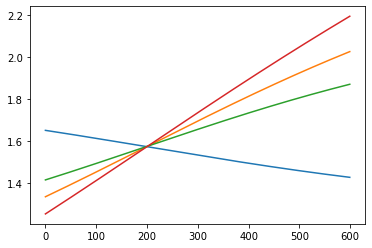

In [21]:
# estimate the AoA from the recived signal
# method 1: 1-d AoA estimation with multiple antenna pairs
from itertools import combinations
antenna_pair_index_list = [(0, 1), (0, 2), (0, 3), (1, 2)]
num_antenna_pair = len(antenna_pair_index_list)

t_aggregate = 0.1
num_t_sample = int(duration.total_seconds()/t_aggregate)
theta = np.empty((num_antenna_pair, num_t_sample))

for i in range(num_antenna_pair):
    antenna_index = antenna_pair_index_list[i]
    sig_1, sig_2 = received_sig[antenna_index[0], :], received_sig[antenna_index[1], :]
    delta_phi = np.angle(np.multiply(sig_1, sig_2.conj()))
    theta_tmp = np.arccos(delta_phi*c/2/np.pi/fc/d)
    theta[i, :] = np.angle(np.mean((np.exp(1j*theta_tmp.reshape(-1, int(t_aggregate*fs)))), axis=1))
    plt.plot(theta[i, :])
plt.show()

# TODO: How to intersect them ?

In [67]:
def aoa_music_2d(x, M_x, M_y, d, lam):
    x_ = x
    num_sample = x_.shape[1]
    num_ante = x_.shape[0]
    num_sig = 1
    M = M_x*M_y
    S = x_ @ np.conjugate(x_.T)/num_sample
    eig_va, eig_ve = np.linalg.eigh(S)
    eigs_ve_sort = np.argsort(eig_va)[::-1]
    E_N = np.zeros((num_ante, num_ante - num_sig), dtype=np.complex64)
    for i in range(num_ante - num_sig):
        E_N[:,i] = eig_ve[:,eigs_ve_sort[num_sig+i]]
    theta_hat = np.arange(0, 90, 0.5)
    phi_hat = np.arange(0, 360, 1)
    music_spec = np.zeros((len(theta_hat), len(phi_hat)), dtype=np.complex64)
    for i in range(len(theta_hat)):
        for j in range(len(phi_hat)):
            theta_ = theta_hat[i]
            phi_ = phi_hat[j]
        
            a_x = np.exp(-1j*2*np.pi*d/lam*np.arange(0, M_x, 1)*np.cos(np.deg2rad(theta_)*np.cos(np.deg2rad(phi_)))).T
            a_y = np.exp(-1j*2*np.pi*d/lam*np.arange(0, M_y, 1)*np.cos(np.deg2rad(theta_)*np.sin(np.deg2rad(phi_)))).T
            a = np.kron(a_x, a_y)
            music_spec[i, j] = a.conj().T @ E_N @ E_N.conj().T @ a
    return np.abs(music_spec)

In [40]:
my_var = {'rx_': received_sig}
scipy.io.savemat('my_file_.mat', {'my_var_new': my_var})

In [20]:
dist = {'d': d}
scipy.io.savemat('dist.mat', {'dist': dist})

In [69]:
recv = {'rx': received_sig[:, 0:500]}
scipy.io.savemat('tmp.mat', {'recv': recv})

In [17]:
len(n)

(600, 6)

In [106]:
received_sig_1.shape

(60001,)